<style>
@import url(https://www.numfys.net/static/css/nbstyle.css);
</style>
<a href="https://www.numfys.net"><img class="logo" /></a>

# Intermediate NumPy

### Modules - Basics
<section class="post-meta">
By Thorvald Ballestad, Niels Henrik Aase, Eilif Sommer Øyre and Jon Andreas Støvneng
</section>
Last edited: November 21th 2019

---

В этом блокноте мы рассмотрим некоторые из наиболее распространенных функций NumPy.
Он задуман как продолжение основ NumPy ([ссылка](https://nbviewer.jupyter.org/urls/www.numfys.net/media/notebooks/introduction_to_numpy.ipynb)).
Тетрадь довольно длинная.
Различные разделы предназначены для самостоятельного чтения, поэтому не стесняйтесь переходить к разделу, который вас интересует.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Содержание

- [Массивы различных форм](#Arrays-of-different-shapes)
- [Нарезка и индексирование](#Slicing-and-indexing)
- [Мешгрид](#Meshgrid)
- [Комплексные числа](#Complex-numbers)
- [Чтение и запись в файл](#Reading-and-writing-to-file)
- [Полезные функции NumPy](#Useful-NumPy-functions-and-examples-of-usage)

## Arrays of different shapes
Массивы могут иметь любые размеры и форму, которые мы пожелаем. 
Давайте преобразуем
$$
(0, 1, 2, 3, 4, 5, 6, 7, 8)
$$
в
$$
\begin{bmatrix}
0 & 1 & 2\\
3 & 4 & 5\\
6 & 7 & 8
\end{bmatrix}.
$$

In [2]:
# Создаем матрицу 3x3

A = np.arange(9)  # Точки от 0 до 8, с интервалом 1
print("A before reshape:", A)
A = A.reshape((3,3))  # Установливаем форму 3x3
print("A after reshape:")
print(A)

A before reshape: [0 1 2 3 4 5 6 7 8]
A after reshape:
[[0 1 2]
 [3 4 5]
 [6 7 8]]


In [3]:
# Мы также можем получить пустой массив с заданным размером с помощью np.zeros
np.zeros((4, 2))

array([[0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.]])

Двумерные массивы можно использовать так же, как матрицы, что позволяет легко выражать наши математические выражения в коде. В NumPy символом для умножения матриц или векторов является @.

In [4]:
x = np.array([0, 1, 2])
print(A @ x)  # Print the result of A matrix multiplied with x

[ 5 14 23]


Подробнее о линейной алгебре в NumPy читайте [блокнот](https://nbviewer.jupyter.org/urls/www.numfys.net/media/notebooks/linear_algebra_in_python.ipynb), который охватывает решение системы уравнений, задачи на собственные значения и многое другое.

Наличие массивов в форме матрицы становится особенно полезным, как только мы научимся нарезке.

## Slicing and indexing
Когда у нас есть массивы, будь то одномерные или многомерные, полезно иметь возможность получать группы элементов, точно так же, как мы это делаем с индексацией в обычных списках.

Давайте сначала рассмотрим обычные списки.
Помните, что списки индексируются с 0.

In [5]:
my_list = [1,2,3,4]  # Обычный список Python

# Мы можем получить доступ к различным частям списка путем нарезки и индексирования:
print("my_list[0]:\t", my_list[0])     # Первый элемент
print("my_list[:2]:\t", my_list[:2])   # Два первых элемента
print("my_list[-2:]:\t", my_list[-2:]) # Последние два элемента

my_list[0]:	 1
my_list[:2]:	 [1, 2]
my_list[-2:]:	 [3, 4]


В общем случае синтаксис для нарезки списков выглядит как `my_list[start:end:step]`, где `start` - это первый элемент, который нам нужен, `end` - последний элемент (не включая), а `step` - размер шага.
Обратите внимание, что если `начало` или `конец` пусты, они будут нарезаться от начала или до конца соответственно.
Отрицательные значения отсчитываются с конца, так что -1 является последним элементом.

Если вы совершенно не знакомы с подобным, вам рекомендуется поиграть с этим сейчас, прежде чем переходить к нарезке массива.

Мы можем сделать то же самое с массивами, но у массивов есть еще больше способов нарезки!

Синтаксис для нарезки в NumPy точно такой же, как и для списков, но мы можем сделать это для каждого измерения!
Для двумерного массива синтаксис становится `my_array[start_1:end_1, start_2:end_2]`, где `start_1` и `end_1` - начальные и конечные значения для первой оси, и аналогично с `start_2` и `end_2` для второй оси.

Давайте еще раз рассмотрим матрицу 
$$
A = 
\begin{bmatrix}
0 & 1 & 2\\
3 & 4 & 5\\
6 & 7 & 8
\end{bmatrix}
$$
представленную в виде массива.

In [6]:
# Формирует массив
# A = [0, 1, 2]
#     [3, 4, 5]
#     [6, 7, 8]
A = np.arange(9).reshape((3,3))

In [7]:
# Давайте обратимся к некоторым элементам

# A_00, первая строка, первый столбец (помните индексация начинается с 0, в математической нотации будет A_11)
print("A_00:", A[0,0])

# A_02, первая строка, третий столбец
print("A_02:", A[0,2])

# A_21, третья строка, последний второй столбец
print("A_21:", A[2,1])

A_00: 0
A_02: 2
A_21: 7


In [8]:
# Мы можем пойти еще дальше и получить целые столбцы и строки

# Первый ряд А
print("First row:", A[0])

# Первая колонка А
print("First column:", A[:,0])

First row: [0 1 2]
First column: [0 3 6]


Как вы помните `:` означает все элементы, так как и `start`, и `end` не заданы.
Например, `my_list[:]` просто дает нам `my_list`.
В `A[:, 0]` мы имеем в виду "все строки нулевого столбца".
Основываясь на этой нотации, мы помним, что `my_list[1:]` дает нам весь список, начиная со второго элемента.
Мы можем использовать это в массивах, чтобы получить части столбца или строки.

In [9]:
# Первый столбец A, начиная со второго элемента в столбце
print("A[1:, 0]:", A[1:, 0])

# Конечно, мы можем получить и другие столбцы
print("A[1:, 2]:", A[1:, 2])

A[1:, 0]: [3 6]
A[1:, 2]: [5 8]


Попробуйте разобраться, почему следующая строка дает нам тот результат, который она дает:

In [34]:
print('A[1:, 1:]:')
print(A[1:, 1:])
# Оба среза 1: исключают первую строку и первый столбец;
# остаётся правый нижний блок [[4, 5], [7, 8]].

A[1:, 1:]:
[[4 5]
 [7 8]]


## Meshgrid

Поначалу Meshgrid может показаться запутанным, но он очень полезен.
Прежде чем объяснить, что такое сетка, давайте объясним, зачем они нам нужны.
Представьте, что вы должны построить тепловую карту, то есть 2D-график, где каждой точке на плоскости задается цвет, зависящий от значения функции, которую вы строите.
Напомним, что при построении графика в "matplotlib", о котором вы можете прочитать подробнее [здесь](https://nbviewer.jupyter.org/urls/www.numfys.net/media/notebooks/basic_plotting.ipynb), нужно предоставить два списка, один с $x$-значениями и один с $y$-значениями.
Это дает набор точек, в которых будет строиться функция.

При построении графика на плоскости требуется три списка значений, координаты $x$ и $y$ и значения функций в каждой точке.
Для каждого значения $x$ мы хотим перебрать все значения $y$, чтобы охватить каждую точку.
Однако, если мы просто передадим наши массивы $x$- и $y$-напрямую, мы получим только одну точку для каждого значения $x$, а также для значений $y$.
Вот тут-то и вступает в игру "мешгрид".
Для двумерного случая это даст нам два массива, где каждое значение повторяется таким образом, что два списка образуют сетку.
Это лучше продемонстрировать на примере.

In [11]:
x = np.arange(0, 5)
y = np.arange(2, 5)

xx, yy = np.meshgrid(x, y)
print('x =',x, ', y =', y, '\n')
print(xx, '\n')
print(yy)

x = [0 1 2 3 4] , y = [2 3 4] 

[[0 1 2 3 4]
 [0 1 2 3 4]
 [0 1 2 3 4]] 

[[2 2 2 2 2]
 [3 3 3 3 3]
 [4 4 4 4 4]]


Обратите внимание, что если бы вы извлекли соответствующие элементы в `xx` и `yy`, то есть элементы с одинаковым положением в матрицах, вы получили бы пары значений $x$ и $y$. Таким образом, мы присвоили координаты каждой точке, как и хотели! Также стоит отметить, что `xx` и `yy` имеют одинаковую форму.
Теперь мы можем построить график нашего результата.

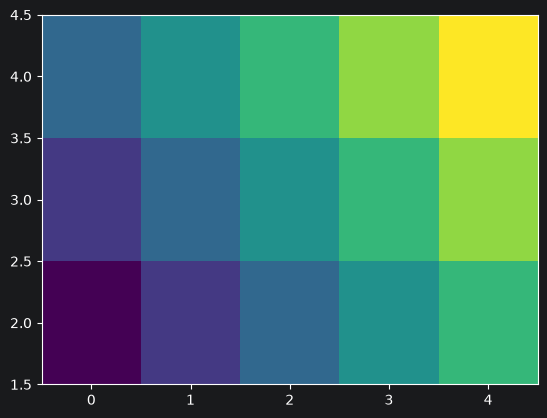

In [12]:
plt.pcolormesh(xx, yy, xx + yy)  # pcolormesh строит тепловую карту
plt.show()

**Соображения о скорости вычислений**:

Мешгрид полезен не только для построения графиков.
Это позволяет нам очень легко вычислять значения по нескольким значениям.
Помните, что с помощью NumPy мы можем вычислить значение по массиву, просто передав массив в функцию.
Это поможет избежать использование вложенных циклов `for`, что значительно ускоряет наши вычисления и облегчает написание и чтение кода.

Mehsgrid полезны для всех функций, которые являются функциями двух переменных. В качестве примера мы рассмотрим установившуюся амплитуду затухающего гармонического осциллятора известную в классической механике:
$$
\Theta_0(q, \omega_D) = \frac{F_D}{(\omega_0^2 + \omega_D^2)^2 + (q\omega_D)^2},
$$
где $F_D$ является движущей силой, $\omega_0$ это собственная частота осциллятора, $q$ - коэффициент затухания, а $\omega_D$ - частота возбуждения.

Мы хотим посмотреть на эту амплитуду для разных $q$ и $\omega_D$.

In [13]:
def amplitude(omega, omega_drive, q):
    """Амплитуда управляемого гармонического осциллятора
    с собственной частотой omega, внешней силой с
частотой, заданной omega_drive, и демпфированой
    постоянной q. Здесь движущая сила F_D равна 1."""
    
    return 1/np.sqrt((omega**2-omega_drive**2)**2 + (q*omega_drive)**2)

omega = 1
q = np.linspace(0.5, 1.5, 20)
omega_D = omega * np.linspace(0.5, 1.5, 40)

qq, omega_DD = np.meshgrid(q, omega_D)

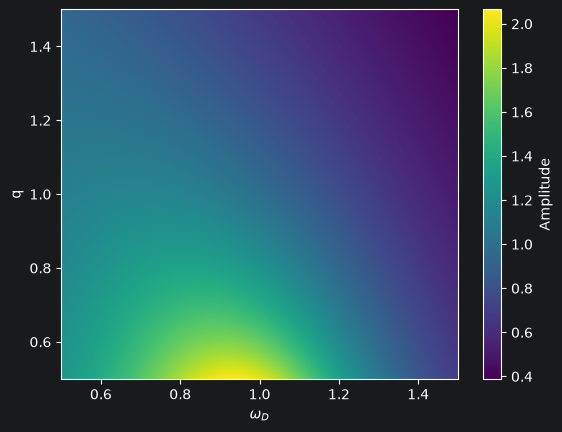

In [36]:
# Вычисляем амплитуду для каждого omega_D и q
a = amplitude(omega, omega_DD, qq)
# Если X и/или Y являются 1-D массивами, они будут расширены 
# по мере необходимости в соответствующие 2-D массивы.
# Т. е. в этом случае нет необходимости в np.meshgrid.
plt.pcolormesh(omega_D, q, a.T)  # a.T возвращает транспонированную а
plt.colorbar(label='Amplitude')
plt.ylabel("q")
plt.xlabel("$\\omega_D$")
plt.show()

Теперь мы рассмотрим время расчета.
Для этого мы будем использовать функцию Jupyter `%timeit`.
Он вычисляет время, необходимое для выполнения команды или ячейки.
Строки с префиксом `%timeit` будут синхронизированы сами по себе.
`%%timeit` выдает время для всей ячейки.

In [37]:
%timeit a = amplitude(omega, omega_DD, qq)

31.9 ms ± 445 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [38]:
%%timeit
# Эквивалентная калькуляция с использованием циклов for.
a_python = []
for oD in omega_D:
    for q_val in q:
        a_python.append(amplitude(omega, oD, q_val))

1.9 s ± 42.1 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


При времени вычислений 9,0$\mu$s и 2,2 мс очевидно, что разница во времени вычислений существенна!
Скорость вычислений будет иметь большое значение по мере увеличения размера данных.

In [39]:
# Greatly increase the number of points from previous example!
omega = 1
q = np.linspace(0.5, 1.5, 1000)
omega_D = omega * np.linspace(0.5, 1.5, 2000)

qq, omega_DD = np.meshgrid(q, omega_D)
%timeit a = amplitude(omega, omega_DD, qq)

32.2 ms ± 786 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [40]:
%%timeit
a_python = []
for oD in omega_D:
    for q_val in q:
        a_python.append(amplitude(omega, oD, q_val))

1.88 s ± 11.8 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


Для любопытного читателя мы упомянем, что это также могло быть достигнуто с помощью функции вещания NumPy.
Это более прямой метод, но менее интуитивный.

## Complex numbers

NumPy имеет встроенную поддержку комплексных чисел.
Они интуитивно понятны в работе и позволяют легко вводить математику в код.

NumPy использует `j` в мкачестве мнимой единицы.
Давайте посмотрим на это в действии.

In [19]:
print(1j**2)  # Должно дать -1

(-1+0j)


Чтобы NumPy понял, что мы хотим работать с комплексными числами, мы должны явно задать мнимую часть, даже если она равна нулю.

In [43]:
# Fails
print(np.sqrt(-1))

# Works
print(np.sqrt(-1+0j))

nan
1j


C:\Users\Pasha\AppData\Local\Temp\ipykernel_21924\4201278770.py:2: RuntimeWarning: invalid value encountered in sqrt
  print(np.sqrt(-1))


In [21]:
# Массив с мнимыми числами от 0 до 2pi j
a = np.linspace(0+0j, 2*np.pi*1j, 50)

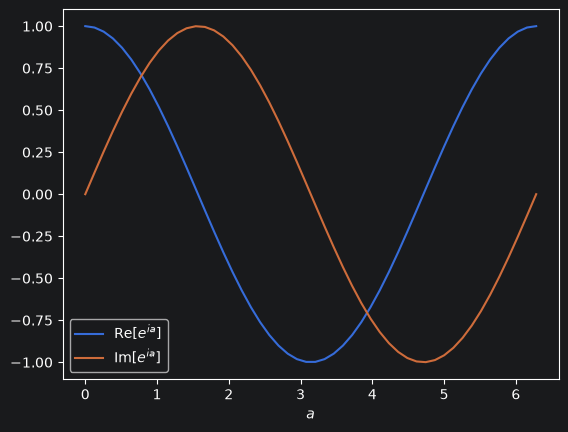

In [22]:
plt.plot(np.abs(a), np.real(np.exp(a)), label=r'Re$[e^{ia}]$')  # Plot real value of np.exp(a)
plt.plot(np.abs(a), np.imag(np.exp(a)), label=r'Im$[e^{ia}]$')  # Plot imaginary value of np.exp(a)
plt.legend()
plt.xlabel('$a$')
plt.show()

Мы наблюдаем разность фаз $90^{\circ}$ между действительной и мнимой частью, как и ожидалось.

## Reading and writing to file

Использование только встроенных функций Python для чтения и записи в файлы может быть утомительным.
NumPy имеет функции, разработанные специально для чтения и записи структурированных данных, `np.loadtxt` и `np.savetxt`.
Функции очень мощные и имеют множество опций.
Здесь мы сосредоточимся на базовом использовании и отсылаем читателя к документации NumPy для более углубленного использования.

Файл данных, используемый в этом примере, можно найти [здесь](https://numfys.net/media/notebooks/files/intermediate_numpy_my_data.txt).

`loadtxt` прочитает данные в файле, преобразует их в соответствующий тип данных и сохранит в массиве NumPy.
Давайте посмотрим на это в действии.

In [24]:
# From the header line in my_data.txt,
# we know that the file is in the format
# time  temperature  wind
data = np.loadtxt('images/my_data.txt')
print(data)

[[ 0.  15.   2. ]
 [ 1.  16.5  2.8]
 [ 2.  18.   3.1]
 [ 3.  20.   2.7]
 [ 4.  19.   1.9]
 [ 5.  17.5  2.2]]


Обратите внимание, что каждая строка в нашем массиве соответствует времени.
Часто было бы удобнее иметь каждый ряд данных в своем собственном массиве, например, если бы мы хотели изобразить наши данные на графике.
Мы могли бы достичь этого с помощью нарезки NumPy, но у `loadtxt` есть более прямой способ сделать это.

In [25]:
t, temperature, wind = np.loadtxt('images/my_data.txt', unpack=True)

`unpack=True` транспонирует наши данные так, чтобы каждая строка представляла одно поле, в данном примере время, температуру и скорость ветра.
Таким образом, мы можем легко считать данные в наши переменные `t`, `temperature`, и `wind`.

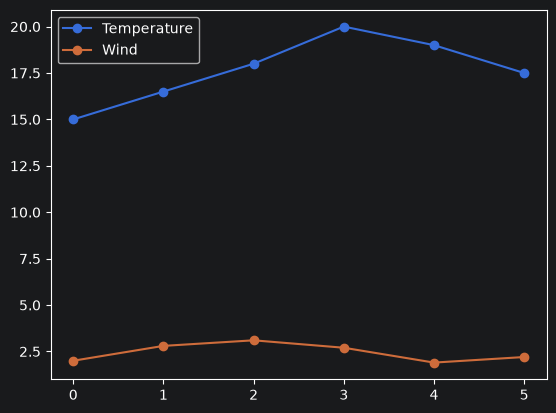

In [26]:
plt.plot(t, temperature, 'o-', label="Temperature")
plt.plot(t, wind, 'o-', label="Wind")
plt.legend();

Теперь мы сгенерируем некоторые новые данные, которые мы можем сохранить в файл, `my_new_data.txt`.

In [27]:
# Среднее значение температуры
T_mean = np.mean(temperature)
# Отклонение от среднего значения в каждый момент времени
delta_temperature = temperature - T_mean
# Сохранить в файл
np.savetxt('my_new_data.txt', np.transpose((t, delta_temperature)))

`savetxt` принимает данные для записи в файл в качестве второго аргумента, в данном примере это `np.transpose((t, delta_temperature))`.
Можно спросить, зачем транспонирование; мы хотим, чтобы `t` и `delta_temperature` были столбцами, а не строками, чтобы новый файл имел тот же формат, что и наш входной файл.

## Useful NumPy functions and examples of usage
В этом разделе вы найдете некоторые полезные функции с кратким объяснением.
Для более подробного объяснения, пожалуйста, посетите документацию NumPy.
После списка функций исследуйте некоторым примерам использования NumPy для решения различных проблем, с которыми можно столкнуться.

**Некоторые полезные функции:**
- `np.amin`, `np.amax`. Возвращает минимальное и максимальное значение массива.

- `np.argmin`, `np.argmax`. Возвращает индекс минимального и максимального значения массива.
- `np.argwhere`. Возвращает индексы, в которых условие истинно. Например
```
a = np.array([0,1,2,3,10])
np.argwhere(a>1)
```
вернет `[2,3,4]`.

### Коэффициенты волновой функции
Физика этого примера не важна для понимания NumPy.
Если вы ее не понимаете, не волнуйтесь!

Из линейной алгебры мы знаем, что при ортонормированном базисе $B$ из $V$ любой вектор $v\in V$ может быть записан как линейная комбинация векторов $b \in B$ .
Мы также знаем, что коэффициент $b\in B$ для некоторого $v\in V$ задается
$$
c_b = \langle b, v\rangle.
$$

Это часто используется в физике, вероятно, наиболее примечательно в квантовой механике.
Ниже приводится краткий пример использования NumPy для линейной алгебры, чтобы вычислить коэффициенты для различных волновых функций.

In [28]:
x = np.linspace(0, 1, 5000)
dx = x[1] - x[0]

# Базисные волновые функции для потенциала частицы в ящике
# Эти функции могут быть легко выведены с помощью базовой квантовой механики
g1 = lambda x: np.sqrt(2)*np.sin(np.pi*x)
g2 = lambda x: np.sqrt(2)*np.sin(2*np.pi*x)
g3 = lambda x: np.sqrt(2)*np.sin(3*np.pi*x)

# Создает несколько линейных комбинаций
y1 = g1(x) + g2(x)
y2 = g1(x) + 2*g2(x)
y3 = 0.2*g1(x) + 10*g3(x)

# Складывает функции вертикально, создавая матрицы
basis_functions = np.vstack((g1(x), g2(x), g3(x)))
my_functions = np.vstack((y1, y2, y3))

# матричное умножение
basis_functions*dx @ my_functions.T

array([[ 1.00000000e+00,  1.00000000e+00,  2.00000000e-01],
       [ 1.00000000e+00,  2.00000000e+00, -3.70038201e-16],
       [ 2.12340995e-16,  1.08447322e-16,  1.00000000e+01]])

Теперь мы можем прочитать коэффициенты каждой функции `y1`, `y2` и `y3` из столбцов.
Например, в первом столбце показано, что `y1` имеет коэффициенты 1, 1 и $1.7\cdot 10^{-15}\approx 0$, как и ожидалось.

### Найти минимумы функции
Рассмотрим функцию 
$$
f(x) = -\frac{1}{6}x^3 + 2x.
$$

Найдите ее локальные минимумы.

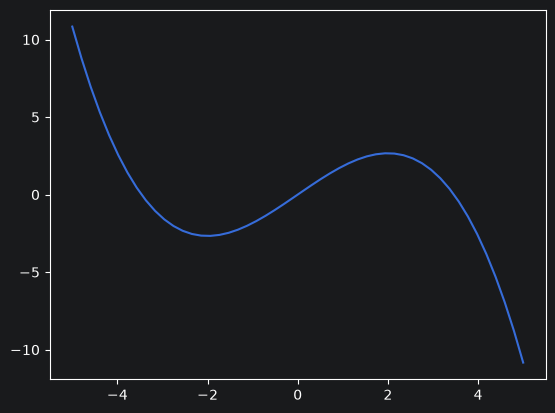

In [29]:
x = np.linspace(-5, 5, 50)

def f(x):
    return -x**3/6 + 2*x
plt.plot(x, f(x))
plt.show()

Мы видим, что локальный минимумы слева от 0 и что есть меньшие значения, чем этот минимум справа от нуля.
Поэтому разумно ограничить наш список $x$ отрицательными значениями.
```
x[x<0]
```
Теперь мы просто передаем этот массив в `f` и находим его минимумы, используя `np.min`.

In [30]:
np.min(f(x[x<0]))
y_min = np.min(f(x[x<0]))

Это дает нам значение $y$ в локальных минимумах.
Мы также хотим найти соответствующее значение $x$.
`np.argmin` дает нам индекс значения $y$ с минимальным значением, использование этого индекса в массиве $x$ дает нам соответствующее значение.

In [33]:
min_arg = np.argmin(f(x[x<0]))
x_min = x[x<0][min_arg]
print(f"(x,y) = {x_min:.2f}, {y_min:.2f}")
# f'(x)=2-x**2/2=0 при x=±2; f''(-2)=2>0.
# Единственный локальный минимум: x=-2, f(x)=-8/3.
print('Точный локальный минимум:', -2, -8/3)

(x,y) = -1.94, -2.66
Точный локальный минимум: -2 -2.6666666666666665


#### Некоторые общие соображения, касающиеся скорости вычислений

Основным преимуществом использования NumPy в вычислениях, в дополнение к простому и интуитивно понятному способу написания нашего кода, является значительно увеличенная скорость вычислений.
Вот некоторые моменты, которые стоит запомнить, чтобы наилучшим образом воспользоваться этим.

**Используйте массивы NumPy!**
Самым важным шагом является фактическое использование массивов NumPy.
За некоторыми исключениями, все списки, которые используются, должны быть массивами NumPy.

**Используйте функциональность NumPy.**
Неопытные пользователи NumPy имеют тенденцию решать свои проблемы, используя более традиционные питонические решения, когда было бы выгодно использовать функциональность NumPy.
Например, очень редко нужно использовать циклы "for", так как они часто могут быть заменены операциями NumPy, которые намного быстрее.

**Не добавляйте элементы в массивы NumPy.**
Эта операция значительно медленнее, чем инициализация массива и последующая запись в него.
Хорошим примером являются итерационные методы с фиксированным числом итераций, такие как метод Эйлера.
Инициализация массива $y$ сначала нулями (`np.zeros`) или пустыми значениями (`np.empty`) выполняется быстрее, чем добавление на каждом временном шаге.